# Laboratorium 4 — Obsługa długich sekwencji: LSTM, GRU, splot 1D

**Cel:** pokazać, że prosty RNN nie radzi sobie z zależnościami długozasięgowymi,
a LSTM, GRU i rozszerzony (dilated) Conv1D — tak. Benchmark: klasyczny **adding problem**.

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 1. Instalacja i import

In [1]:
!pip -q install torch numpy matplotlib

In [2]:
import time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'; print('Urządzenie:', DEVICE)

Urządzenie: cpu


## 2. Dane: adding problem

Sekwencja par (wartość, znacznik). Dokładnie dwie pozycje mają znacznik = 1.
Cel = suma wartości na oznaczonych pozycjach. Model musi zapamiętać dwie liczby
odległe o wiele kroków. Predykcja średniej daje MSE ≈ 0.167.

In [3]:
def gen(N, L):
    val = np.random.rand(N, L, 1).astype(np.float32)
    mark = np.zeros((N, L, 1), np.float32)
    y = np.zeros((N, 1), np.float32)
    for i in range(N):
        p = np.random.choice(L, 2, replace=False)
        mark[i, p, 0] = 1.0
        y[i, 0] = val[i, p, 0].sum()
    x = np.concatenate([val, mark], axis=2)   # [N, L, 2]
    return torch.tensor(x).to(DEVICE), torch.tensor(y).to(DEVICE)

# Podgląd jednego przykładu
xx, yy = gen(1, 20)
poz = np.where(xx[0,:,1].cpu().numpy()==1)[0]
print('Oznaczone pozycje:', poz)
print('Wartości tam:', xx[0,poz,0].cpu().numpy().round(3), ' suma (cel):', float(yy[0,0]))

Oznaczone pozycje: [11 13]
Wartości tam: [0.529 0.926]  suma (cel): 1.4544916152954102


## 3. Modele

Cztery architektury o zbliżonej pojemności: SimpleRNN, LSTM, GRU oraz stos
rozszerzonych splotów 1D (dilation 1→16) z globalnym uśrednianiem.

In [4]:
class RNNNet(nn.Module):
    def __init__(self, typ, hidden=64):
        super().__init__()
        self.rnn={'RNN':nn.RNN,'LSTM':nn.LSTM,'GRU':nn.GRU}[typ](2,hidden,batch_first=True)
        self.fc=nn.Linear(hidden,1)
    def forward(self,x):
        out,_=self.rnn(x); return self.fc(out[:,-1,:])

class ConvNet(nn.Module):
    def __init__(self, ch=64):
        super().__init__()
        self.net=nn.Sequential(
            nn.Conv1d(2,ch,3,padding=1,dilation=1),nn.ReLU(),
            nn.Conv1d(ch,ch,3,padding=2,dilation=2),nn.ReLU(),
            nn.Conv1d(ch,ch,3,padding=4,dilation=4),nn.ReLU(),
            nn.Conv1d(ch,ch,3,padding=8,dilation=8),nn.ReLU(),
            nn.Conv1d(ch,ch,3,padding=16,dilation=16),nn.ReLU())
        self.fc=nn.Linear(ch,1)
    def forward(self,x):
        h=self.net(x.transpose(1,2)).mean(dim=2); return self.fc(h)

def licz_parametry(m): return sum(p.numel() for p in m.parameters())

## 4. Uczenie i ewaluacja

In [5]:
def trenuj(model, L, epoki=30, N=4000, lr=5e-3, batch=128):
    model=model.to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=lr); Lf=nn.MSELoss()
    Xtr,Ytr=gen(N,L); Xte,Yte=gen(800,L)
    t0=time.time()
    for ep in range(epoki):
        model.train(); perm=torch.randperm(N)
        for i in range(0,N,batch):
            idx=perm[i:i+batch]; opt.zero_grad()
            Lf(model(Xtr[idx]),Ytr[idx]).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
    czas=time.time()-t0
    model.eval()
    with torch.no_grad(): mse=Lf(model(Xte),Yte).item()
    return mse, czas

## 5. Porównanie architektur (L = 50)

Uwaga: na CPU trwa ~1 min. W Colab włącz GPU (Runtime → Change runtime type).

In [6]:
L = 50
modele = {'SimpleRNN': RNNNet('RNN'), 'LSTM': RNNNet('LSTM'),
          'GRU': RNNNet('GRU'), 'Conv1D': ConvNet()}
wyniki = {}
for nazwa, m in modele.items():
    mse, czas = trenuj(m, L)
    wyniki[nazwa] = {'mse': mse, 'czas': czas, 'params': licz_parametry(m)}
    print(f'{nazwa:10s}  MSE={mse:.4f}  czas={czas:4.1f}s  params={licz_parametry(m)}')

SimpleRNN   MSE=0.1783  czas=13.0s  params=4417
LSTM        MSE=0.0007  czas=42.9s  params=17473
GRU         MSE=0.0008  czas=40.3s  params=13121
Conv1D      MSE=0.0002  czas=76.2s  params=49921


## 6. Wykres porównawczy

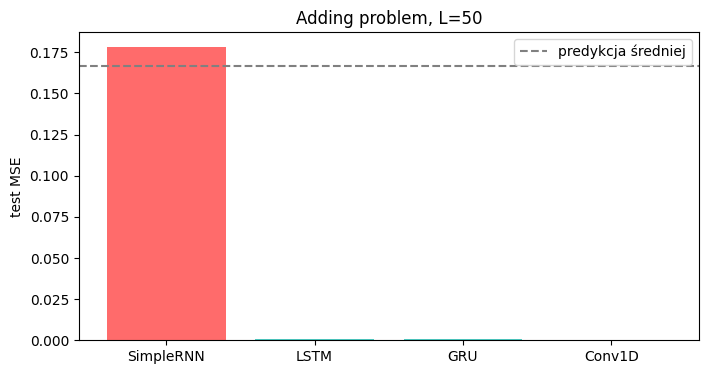

In [7]:
nazwy = list(wyniki.keys())
mse = [wyniki[n]['mse'] for n in nazwy]
plt.figure(figsize=(8,4))
plt.bar(nazwy, mse, color=['#ff6b6b','#4ecdc4','#4ecdc4','#ffd166'])
plt.axhline(0.167, ls='--', color='gray', label='predykcja średniej')
plt.ylabel('test MSE'); plt.title(f'Adding problem, L={L}'); plt.legend(); plt.show()

## 7. (opcjonalnie) Wpływ długości sekwencji

Im dłuższa sekwencja, tym wyraźniejsza przewaga bramek nad prostym RNN.

In [8]:
# Uruchom, by zobaczyć trend (dłużej!). Odkomentuj:
for L in [25, 50, 100]:
    mse,_ = trenuj(RNNNet('RNN'), L); print(f'RNN  L={L}: {mse:.4f}')
    mse,_ = trenuj(RNNNet('GRU'), L); print(f'GRU  L={L}: {mse:.4f}')

RNN  L=25: 0.0975
GRU  L=25: 0.0002
RNN  L=50: 0.1809
GRU  L=50: 0.0006
RNN  L=100: 0.1786
GRU  L=100: 0.0005


## Zadanie na sprawozdanie

1. Porównaj SimpleRNN, LSTM, GRU i Conv1D na „adding problem” dla co najmniej **dwóch** długości `L`.
2. Zestaw w tabeli: test MSE, liczbę parametrów i czas uczenia.
3. Zbadaj wpływ rozmiaru stanu ukrytego (RNN) oraz pola recepcyjnego (Conv1D).
4. Wnioski: kiedy bramki/dilated conv wyraźnie przewyższają prosty RNN?

Format sprawozdania: `00_materialy_wspolne/szablon_sprawozdania.md`.